# 08 — Targeted Hybrid Model Optimization
**Project: Retinopathy Detection System**

## Why this experiment?
Notebook 07 achieved 76.94% validation accuracy. Its class-wise report shows strong class 0 performance but weaker results for classes 1, 3 and 4. This notebook tests one controlled optimization: fine-tune the saved hybrid model with a class-aware focal loss.

**Important evaluation note:** The 733-image validation set has already been used in earlier model comparisons. Results here are exploratory and must not be described as an independent test result. The 85% target is not guaranteed. Do not alter validation labels or split to inflate the score.

This notebook preserves the original hybrid checkpoint and saves the optimized candidate under a new filename.

## 1. Imports and reproducibility

In [1]:
import os, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Python GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.16.1
Python GPU devices: []


## 2. Paths and checkpoint verification

In [2]:
PROJECT_ROOT = Path(r"S:\ISP")
DATA_ROOT = PROJECT_ROOT / "data"
MODEL_DIR = DATA_ROOT / "processed" / "models"
RESULT_DIR = DATA_ROOT / "processed" / "results"

TRAIN_SPLIT = RESULT_DIR / "efficientnetb3_train_split.csv"
VAL_SPLIT = RESULT_DIR / "efficientnetb3_validation_split.csv"
BASE_MODEL_PATH = MODEL_DIR / "hybrid_efficientnetb3_mobilenetv2_final.keras"

for path in [TRAIN_SPLIT, VAL_SPLIT, BASE_MODEL_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

csvs = [p for p in (DATA_ROOT / "raw").rglob("train.csv")
        if "aptos" in str(p).lower()]
if not csvs:
    raise FileNotFoundError("Could not find APTOS train.csv under S:/ISP/data/raw.")
DATASET_DIR = csvs[0].parent
IMAGE_DIR = DATASET_DIR / "train_images"
if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

OPT_MODEL_PATH = MODEL_DIR / "hybrid_optimized_focal.keras"
print("Dataset:", DATASET_DIR)
print("Image folder:", IMAGE_DIR)
print("Original hybrid:", BASE_MODEL_PATH)
print("Optimized candidate will be saved as:", OPT_MODEL_PATH)

Dataset: S:\ISP\data\raw\aptos\aptos2019-blindness-detection
Image folder: S:\ISP\data\raw\aptos\aptos2019-blindness-detection\train_images
Original hybrid: S:\ISP\data\processed\models\hybrid_efficientnetb3_mobilenetv2_final.keras
Optimized candidate will be saved as: S:\ISP\data\processed\models\hybrid_optimized_focal.keras


## 3. Load the same saved training and validation IDs

In [3]:
train_df = pd.read_csv(TRAIN_SPLIT)
val_df = pd.read_csv(VAL_SPLIT)

for frame in (train_df, val_df):
    frame["id_code"] = frame["id_code"].astype(str)
    frame["diagnosis"] = pd.to_numeric(frame["diagnosis"]).astype(int)
    frame["image_path"] = frame["id_code"].apply(lambda x: str(IMAGE_DIR / f"{x}.png"))

missing_train = train_df.loc[~train_df.image_path.apply(os.path.isfile), "image_path"]
missing_val = val_df.loc[~val_df.image_path.apply(os.path.isfile), "image_path"]
if len(missing_train) or len(missing_val):
    raise FileNotFoundError(f"Missing images: train={len(missing_train)}, validation={len(missing_val)}")
if set(train_df.id_code) & set(val_df.id_code):
    raise ValueError("Train and validation image IDs overlap.")
if not train_df.diagnosis.between(0, 4).all() or not val_df.diagnosis.between(0, 4).all():
    raise ValueError("Expected labels 0 through 4.")

print("Train:", len(train_df), "| Validation:", len(val_df))
display(train_df.diagnosis.value_counts().sort_index().to_frame("train_count"))
display(val_df.diagnosis.value_counts().sort_index().to_frame("validation_count"))

Train: 2929 | Validation: 733


,train_count
diagnosis,
0,1444
1,296
2,799
3,154
4,236


,validation_count
diagnosis,
0,361
1,74
2,200
3,39
4,59


## 4. Build input pipelines

In [4]:
IMG_SIZE = 300
BATCH_SIZE = 8  # If memory errors occur, reduce to 4.
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # Keep 0..255 for EfficientNet branch.
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame.image_path.values, frame.diagnosis.values.astype(np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
xb, yb = next(iter(train_ds))
print("Image batch:", xb.shape, "| Labels:", yb.shape)
print("Raw pixel range:", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))

Image batch: (8, 300, 300, 3) | Labels: (8,)
Raw pixel range: 0.0 to 255.0


## 5. Inspect training class distribution and focal-loss weights

In [5]:
class_counts = train_df.diagnosis.value_counts().reindex(range(NUM_CLASSES), fill_value=0).sort_index()
counts = class_counts.to_numpy(dtype=np.float32)

# Inverse-square-root frequency weighting is milder than full inverse-frequency weighting.
alpha = 1.0 / np.sqrt(np.maximum(counts, 1.0))
alpha = alpha / alpha.mean()
alpha = np.clip(alpha, 0.60, 1.80)
alpha = alpha / alpha.mean()

print("Training counts:", counts.astype(int).tolist())
print("Focal alpha weights:", np.round(alpha, 3).tolist())
display(pd.DataFrame({"class": range(5), "train_count": counts.astype(int),
                      "focal_alpha": alpha}).round(3))

Training counts: [1444, 296, 799, 154, 236]
Focal alpha weights: [0.5879999995231628, 1.0720000267028809, 0.652999997138977, 1.4869999885559082, 1.2009999752044678]


,class,train_count,focal_alpha
0,0,1444,0.588
1,1,296,1.072
2,2,799,0.653
3,3,154,1.487
4,4,236,1.201


## 6. Load the saved hybrid model

In [6]:
model = tf.keras.models.load_model(BASE_MODEL_PATH)
print("Loaded:", BASE_MODEL_PATH.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total layers:", len(model.layers))

Loaded: hybrid_efficientnetb3_mobilenetv2_final.keras
Input shape: (None, 300, 300, 3)
Output shape: (None, 5)
Total layers: 15


## 7. Define class-aware focal loss

In [7]:
ALPHA_TENSOR = tf.constant(alpha, dtype=tf.float32)
GAMMA = 2.0

def sparse_class_aware_focal_loss(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    y_one_hot = tf.one_hot(y_true, depth=NUM_CLASSES)
    p_t = tf.reduce_sum(y_one_hot * y_pred, axis=-1)
    alpha_t = tf.gather(ALPHA_TENSOR, y_true)
    loss = -alpha_t * tf.pow(1.0 - p_t, GAMMA) * tf.math.log(p_t)
    return tf.reduce_mean(loss)

# Sanity check: the loss must be a finite scalar.
test_loss = sparse_class_aware_focal_loss(
    tf.constant([0, 1, 2, 3, 4]),
    tf.constant([[.8,.05,.05,.05,.05],
                 [.1,.7,.1,.05,.05],
                 [.1,.1,.7,.05,.05],
                 [.1,.1,.1,.6,.1],
                 [.1,.1,.1,.1,.6]], dtype=tf.float32)
)
print("Focal-loss sanity check:", float(test_loss))

Focal-loss sanity check: 0.056052397936582565


## 8. Fine-tune with a conservative learning rate

In [8]:
# Keep the current architecture and trainable-layer configuration.
# A low learning rate limits destructive changes to the pretrained features.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-6),
    loss=sparse_class_aware_focal_loss,
    metrics=["accuracy"]
)

OPT_EPOCHS = 6
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        OPT_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=2e-7, verbose=1
    )
]

history_opt = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=OPT_EPOCHS,
    callbacks=callbacks
)

pd.DataFrame(history_opt.history).to_csv(
    RESULT_DIR / "hybrid_optimized_focal_history.csv", index=False
)
if not OPT_MODEL_PATH.exists():
    model.save(OPT_MODEL_PATH)
print("Saved optimized candidate:", OPT_MODEL_PATH)

Epoch 1/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7439 - loss: 0.3063
Epoch 1: val_loss improved from None to 0.34401, saving model to S:\ISP\data\processed\models\hybrid_optimized_focal.keras

Epoch 1: finished saving model to S:\ISP\data\processed\models\hybrid_optimized_focal.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 979s 3s/step - accuracy: 0.7439 - loss: 0.3063 - val_accuracy: 0.7804 - val_loss: 0.3440 - learning_rate: 2.0000e-06
Epoch 2/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7504 - loss: 0.3143
Epoch 2: val_loss improved from 0.34401 to 0.33795, saving model to S:\ISP\data\processed\models\hybrid_optimized_focal.keras

Epoch 2: finished saving model to S:\ISP\data\processed\models\hybrid_optimized_focal.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 826s 2s/step - accuracy: 0.7504 - loss: 0.3143 - val_accuracy: 0.7735 - val_loss: 0.3380 - learning_rate: 2.0000e-06
Epoch 3/6
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7562 - loss: 0.3172
Epoch 3: val_loss imp

## 9. Plot optimization history

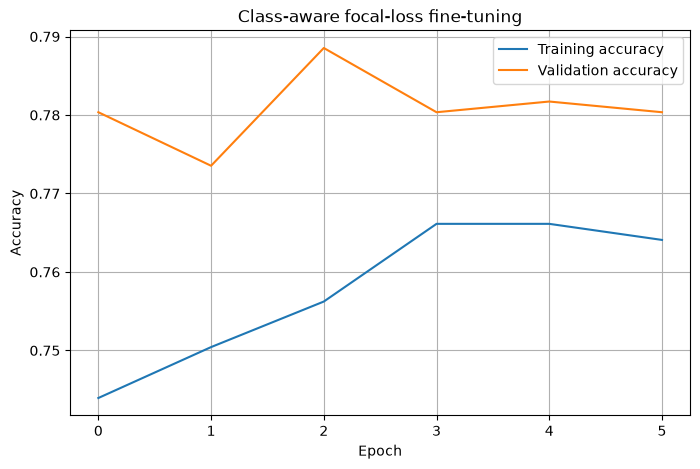

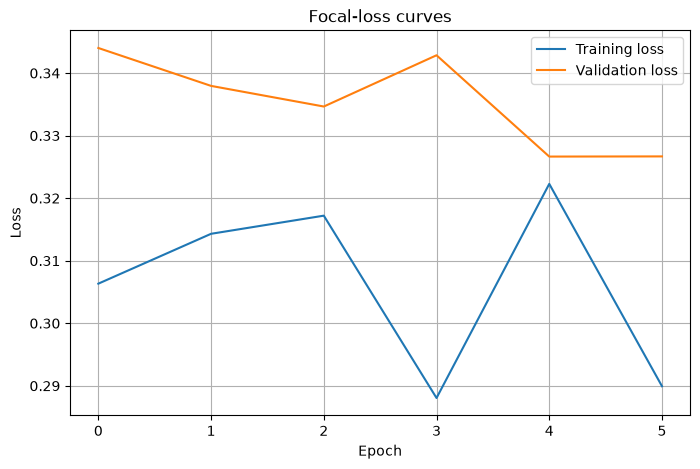

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history_opt.history["accuracy"], label="Training accuracy")
plt.plot(history_opt.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Class-aware focal-loss fine-tuning")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_opt.history["loss"], label="Training loss")
plt.plot(history_opt.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal-loss curves")
plt.grid(True)
plt.legend()
plt.show()

## 10. Evaluate optimized candidate on the same validation set

In [11]:
# Load model without restoring the custom training loss.
best_model = tf.keras.models.load_model(
    OPT_MODEL_PATH,
    compile=False
)

print("Optimized hybrid model loaded successfully!")
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)
y_true = val_df.diagnosis.to_numpy(dtype=int)
y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")

optimized_metrics = {
    "accuracy": float(accuracy),
    "macro_precision": float(precision_macro),
    "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro),
    "quadratic_weighted_kappa": float(qwk),
    "validation_images": int(len(y_true)),
    "evaluation_note": "Exploratory reuse of the validation split already used in earlier model comparisons."
}
print(json.dumps(optimized_metrics, indent=4))
with open(RESULT_DIR / "hybrid_optimized_focal_results.json", "w") as f:
    json.dump(optimized_metrics, f, indent=4)

Optimized hybrid model loaded successfully!
Input shape: (None, 300, 300, 3)
Output shape: (None, 5)
92/92 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step
{
    "accuracy": 0.781718963165075,
    "macro_precision": 0.6281035272517052,
    "macro_recall": 0.6359647273416934,
    "macro_f1": 0.6283633752109191,
    "quadratic_weighted_kappa": 0.8475681056553859,
    "validation_images": 733,
    "evaluation_note": "Exploratory reuse of the validation split already used in earlier model comparisons."
}


## 11. Class-wise classification report

In [12]:
report = classification_report(
    y_true, y_pred, labels=[0,1,2,3,4],
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()
display(report_df.round(4))
report_df.to_csv(RESULT_DIR / "hybrid_optimized_focal_classification_report.csv")

,precision,recall,f1-score,support
0,0.9637,0.9557,0.9597,361.0000
1,0.4479,0.5811,0.5059,74.0000
2,0.7541,0.6900,0.7206,200.0000
3,0.3830,0.4615,0.4186,39.0000
4,0.5918,0.4915,0.5370,59.0000
accuracy,0.7817,0.7817,0.7817,0.7817
macro avg,0.6281,0.6360,0.6284,733.0000
weighted avg,0.7936,0.7817,0.7858,733.0000


## 12. Confusion matrix

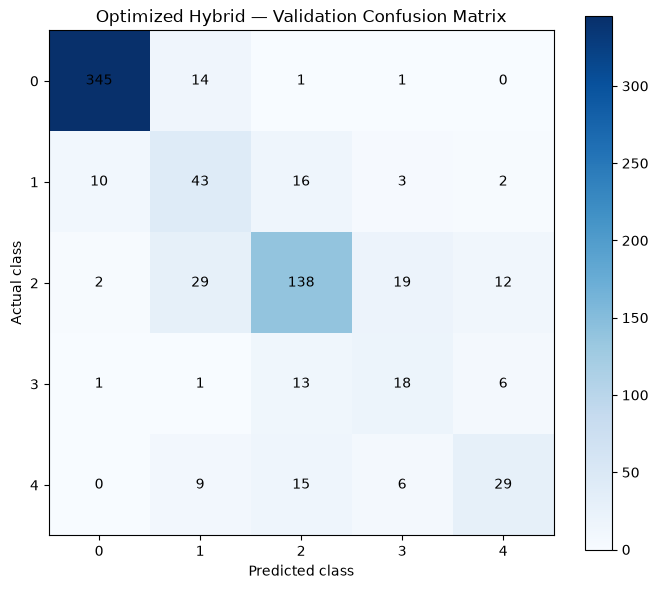

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Optimized Hybrid — Validation Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(RESULT_DIR / "hybrid_optimized_focal_confusion_matrix.png", dpi=200)
plt.show()

## 13. Save predictions and inspect remaining errors

In [14]:
pred_df = val_df[["id_code", "diagnosis"]].copy()
pred_df.rename(columns={"diagnosis": "actual"}, inplace=True)
pred_df["predicted"] = y_pred
pred_df["confidence"] = confidence
for c in range(NUM_CLASSES):
    pred_df[f"prob_class_{c}"] = y_prob[:, c]
pred_df.to_csv(RESULT_DIR / "hybrid_optimized_focal_predictions.csv", index=False)

error_df = pred_df[pred_df.actual != pred_df.predicted].copy()
error_df.to_csv(RESULT_DIR / "hybrid_optimized_focal_errors.csv", index=False)
display(error_df.head(20))
print("Incorrect:", len(error_df), "/", len(pred_df))

,id_code,actual,predicted,confidence,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4
2,61bbc11fe503,4,2,0.337808,0.000522,0.197302,0.337808,0.141702,0.322666
6,44855f666225,2,3,0.806107,0.000054,0.017681,0.155548,0.806107,0.020609
8,1594ca6c30d3,2,4,0.537286,0.000661,0.016835,0.148213,0.297005,0.537286
11,82d364726a58,0,1,0.771983,0.213833,0.771983,0.007281,0.002784,0.004119
13,259d30f693b6,1,0,0.703407,0.703407,0.132702,0.144560,0.002555,0.016776
21,82ac8463fadd,1,0,0.698450,0.698450,0.286258,0.007955,0.001882,0.005455
31,7a6e384a0846,3,1,0.819633,0.127086,0.819633,0.036256,0.007926,0.009100
32,51131b48f9d4,1,2,0.576312,0.001598,0.282319,0.576312,0.111014,0.028757
42,5efa24b03d5e,1,3,0.661908,0.040139,0.292132,0.002006,0.661908,0.003815
44,c0a0828e01b4,3,2,0.640665,0.000108,0.012787,0.640665,0.210735,0.135705


Incorrect: 160 / 733


## 14. Compare baseline hybrid with optimized candidate

In [15]:
baseline_path = RESULT_DIR / "hybrid_validation_results.json"
with open(baseline_path, "r") as f:
    baseline = json.load(f)

comparison = pd.DataFrame([
    {
        "Model": "Hybrid baseline",
        "Accuracy": baseline["accuracy"],
        "Macro Precision": baseline["macro_precision"],
        "Macro Recall": baseline["macro_recall"],
        "Macro F1": baseline["macro_f1"],
        "QWK": baseline["quadratic_weighted_kappa"]
    },
    {
        "Model": "Hybrid focal-loss candidate",
        "Accuracy": accuracy,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro,
        "QWK": qwk
    }
])
display(comparison.round(4))
comparison.to_csv(RESULT_DIR / "hybrid_optimization_comparison.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,QWK
0,Hybrid baseline,0.7694,0.6164,0.6516,0.6253,0.8423
1,Hybrid focal-loss candidate,0.7817,0.6281,0.6360,0.6284,0.8476


## 15. Select a candidate without overwriting the baseline

In [16]:
# Keep the baseline checkpoint intact. This is only a candidate comparison.
baseline_acc = float(baseline["accuracy"])
candidate_acc = float(accuracy)

if candidate_acc > baseline_acc:
    print("The focal-loss candidate has higher validation accuracy.")
elif candidate_acc < baseline_acc:
    print("The baseline hybrid has higher validation accuracy.")
else:
    print("Both have equal validation accuracy; compare macro F1 and QWK too.")

print("Baseline hybrid:", f"{baseline_acc*100:.2f}%")
print("Focal-loss candidate:", f"{candidate_acc*100:.2f}%")
print("Original baseline checkpoint was not overwritten.")

The focal-loss candidate has higher validation accuracy.
Baseline hybrid: 76.94%
Focal-loss candidate: 78.17%
Original baseline checkpoint was not overwritten.


## 16. Final interpretation

- This experiment tests one controlled change: class-aware focal loss with conservative fine-tuning.
- It may improve minority-class recall, but it may also reduce overall accuracy. That trade-off must be measured.
- Keep the original `hybrid_efficientnetb3_mobilenetv2_final.keras` as the baseline.
- The optimized candidate is saved separately as `hybrid_optimized_focal.keras`.
- Since the validation set has already influenced earlier model choices, this score is exploratory. A final independent evaluation requires a separate untouched test set or a new evaluation protocol.
- Do not claim 85% unless the measured result actually reaches it.